![ITQ](img/logoitqv1.jpg)

## 0.1  01PAO 26-26 - Variables Cualitativas

![PYTHON](img/python_logo.png)

Kevin Yalama

[GitHub](https://github.com/kev1n-02/practica-machine.git)

In [1]:
# Creación aleatoria de datos
import numpy as np
X = np.array([0.5, 23, 0.3, 4.5, 0.3, 0.5,
-28, -50, 60, -100, -10, -11, 13, 19, 1, 9])
print(X)


[   0.5   23.     0.3    4.5    0.3    0.5  -28.   -50.    60.  -100.
  -10.   -11.    13.    19.     1.     9. ]


In [2]:
# Medidas de tendencia central
from scipy import stats
media = np.mean(X)
mediana = np.median(X)
moda , _ = stats.mode(X)
print('media: ', media)
print('mediana: ', mediana)
print('moda :', moda)

media:  -4.24375
mediana:  0.5
moda : 0.3


In [3]:
# Medidas de posición
import numpy as np
import matplotlib.pyplot as plt
Q1 = np.percentile(X, 25)
Q3 = np.percentile(X, 75)
RIC = Q3 - Q1
lim_inf = Q1 - 1.5*RIC
lim_sup = Q3 + 1.5*RIC
print('RIC :', RIC)
print('limite inferior :', lim_inf)
print('limite superior :', lim_sup)


RIC : 20.25
limite inferior : -40.625
limite superior : 40.375


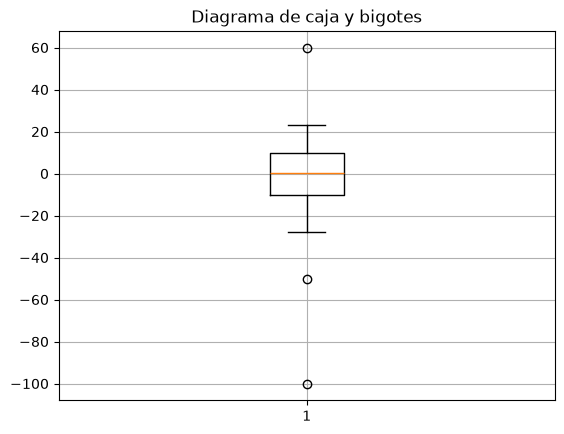

In [4]:
# Dibuja el diagrama de box and whiskers y determina visualmente el número de outliers
plt.boxplot(X)
plt.grid()
plt.title("Diagrama de caja y bigotes")
plt.show()


In [5]:
# Medidas de dispersión
desvest = np.std(X)
print('Desviación típica: ', desvest)
print('Varianza: ', desvest**2)

Desviación típica:  33.521242681880096
Varianza:  1123.6737109375


In [6]:
# Medidas de distribución
asimetria = stats.skew(X)
curtosis = stats.kurtosis(X, fisher=True) # https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kurtosis.html
print('Asimetría ', np.round(asimetria, 4))
print('Curtosis ', np.round(curtosis, 4))

if curtosis>0:
    print('Distribución Leptocúrtica')
elif curtosis<0:
    print('Distribución Platicúrtica')
else:
    print('Distribución Mesocúrtica')


Asimetría  -1.1302
Curtosis  2.2858
Distribución Leptocúrtica


In [7]:
 # Cargar el set de datos de Iris
from sklearn import datasets
from pprint import pprint
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

iris = datasets.load_iris()
pprint(iris)

X = iris.data
y = iris.target

# ¿Qué tipo de asimetría se observa en la variable "longitud del pétalo"?
#???
asimetria = stats.skew(X[:,2])

# ¿A qué tipo de distribución se ajusta la variable "ancho del sépalo", según␣ su curtosis?
#???
curtosis = stats.kurtosis(X[:, 1], fisher=True)


print("Asimetría:", np.round(asimetria, 4))
print("Curtosis:", np.round(curtosis, 4))

{'DESCR': '.. _iris_dataset:\n'
          '\n'
          'Iris plants dataset\n'
          '--------------------\n'
          '\n'
          '**Data Set Characteristics:**\n'
          '\n'
          ':Number of Instances: 150 (50 in each of three classes)\n'
          ':Number of Attributes: 4 numeric, predictive attributes and the '
          'class\n'
          ':Attribute Information:\n'
          '    - sepal length in cm\n'
          '    - sepal width in cm\n'
          '    - petal length in cm\n'
          '    - petal width in cm\n'
          '    - class:\n'
          '            - Iris-Setosa\n'
          '            - Iris-Versicolour\n'
          '            - Iris-Virginica\n'
          '\n'
          ':Summary Statistics:\n'
          '\n'
          '============== ==== ==== ======= ===== ====================\n'
          '                Min  Max   Mean    SD   Class Correlation\n'
          '============== ==== ==== ======= ===== ====================\n'
          '

In [ ]:
# EJERCICIO EXTRA SOBRE EL DATASET DE IRIS
# Extraer la media y la desviación típica de cada variable en función de la clase y representarlo en un gráfico (plt.errorbar)

In [5]:
# Medidas de tendencia central
media = np.mean(X, axis=0)
mediana = np.median(X, axis=0)
moda = stats.mode(X, axis=0)

print("Media:")
print(media)

print("\nMediana:")
print(mediana)

print("\nModa:")
print(moda.mode)

# Medidas de dispersión
desvest = np.std(X, axis=0)
varianza = np.var(X, axis=0)

print("\nDesviación estándar:")
print(desvest)

print("\nVarianza:")
print(varianza)

Media:
[5.84333333 3.05733333 3.758      1.19933333]

Mediana:
[5.8  3.   4.35 1.3 ]

Moda:
[5.  3.  1.4 0.2]

Desviación estándar:
[0.82530129 0.43441097 1.75940407 0.75969263]

Varianza:
[0.68112222 0.18871289 3.09550267 0.57713289]


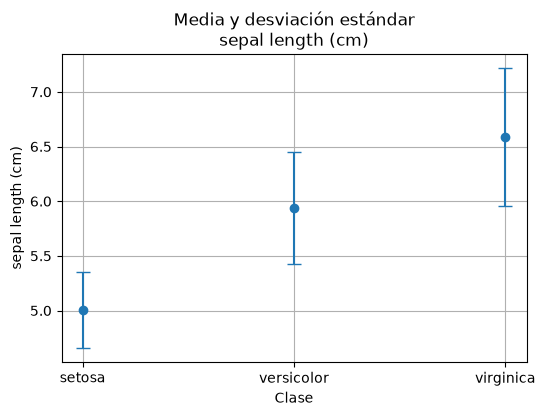

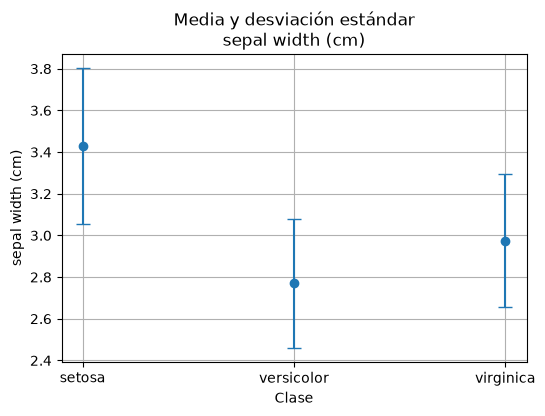

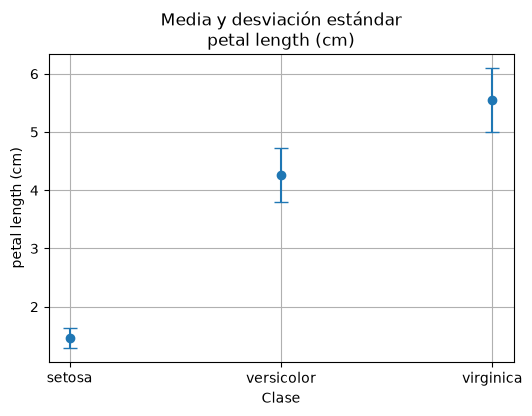

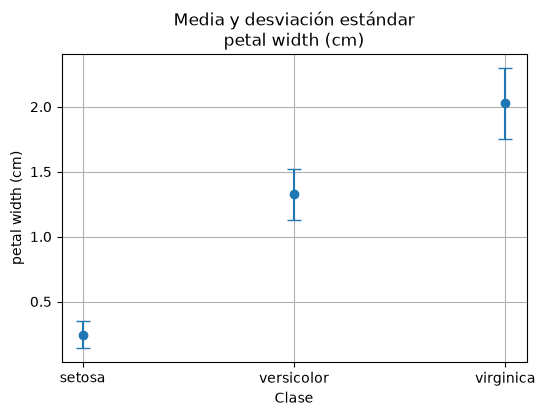

In [8]:
# Nombres de las variables
variables = iris.feature_names

# Recorrer las 4 variables
for i in range(4):

    medias = []
    desviaciones = []

    # Calcular media y desviación para cada clase
    for clase in range(3):
        datos = X[y == clase, i]
        medias.append(np.mean(datos))
        desviaciones.append(np.std(datos))

    # Crear el gráfico
    plt.figure(figsize=(6,4))

    plt.errorbar(
        iris.target_names,      # Eje X
        medias,                 # Media
        yerr=desviaciones,      # Barras de error
        fmt='o',                # Círculos
        capsize=5               # Tamaño de las barras
    )

    plt.title(f"Media y desviación estándar\n{variables[i]}")
    plt.xlabel("Clase")
    plt.ylabel(variables[i])
    plt.grid(True)

    plt.show()